# FMCW Radar — Range-Doppler Map Pipeline
**Platform:** Drone / UAV | **Carrier:** 24 GHz

Run all cells top-to-bottom. Edit targets in **Step 2** and radar parameters in **Step 1**.

## Step 1 — Imports & Radar Parameters

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.constants import c, pi
from numpy.fft import fft
try:
    import ipywidgets as widgets
    from IPython.display import display
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    widgets = None
    display = None

plt.style.use('ggplot')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

#Notes of how the parametes affect the RD-map
# f increases -> lambda decreases -> Doppler Freq decreases -> Velocity range decreases
# bw ↑ → range_res ↓ → better range resolution 
# Tc : Tc ↓ -> slope ↑ -> beat freq ↑ -> If Tc is too short, beat frequencies become large, and you need a higher sampling rate.
# Tc : Tc ↑ → max velocity ↓ → better velocity resolution
# N affects the range FFT size.
# M ↑ → better velocity resolution and more Doppler bins



# ── Radar hardware ─────────────────────────────────────────────────────────────
f   = 24e9       # Carrier frequency [Hz]
Tc  = 40e-6      # Chirp duration [s] 
bw  = 500e6      # Bandwidth [Hz]
M   = 128        # Number of chirps in CPI / slow-time samples
N   = 2048       # Samples per chirp / fast-time samples
DEFAULT_SNR_DB = 10  # One global SNR setting used by all non-interactive noisy plots

# ── Derived ───────────────────────────────────────────────────────────────────
wavelength = c / f
slope      = bw / Tc
fs         = N / Tc              # ADC sampling rate: one full chirp is sampled by N samples
range_res  = c / (2 * bw)
rmax       = c * fs / (4 * slope)
max_vel    = wavelength / (4 * Tc)
vel_res    = wavelength / (2 * M * Tc)


#MENTAL MAP
# f  → wavelength → velocity axis
# bw → range resolution + slope
# Tc → slope + velocity limits
# N  → fs + range bins + max range
# M  → Doppler bins + velocity resolution

print('─── Radar Parameters ──────────────────────────────')
print(f'  Carrier        : {f/1e9:.0f} GHz')
print(f'  Bandwidth      : {bw/1e6:.0f} MHz')
print(f'  Chirp duration : {Tc*1e6:.0f} µs')
print(f'  Chirps (M)     : {M}')
print(f'  Samples (N)    : {N}')
print(f'  ADC fs         : {fs/1e6:.2f} MHz')
print('─── Performance ───────────────────────────────────')
print(f'  Range res      : {range_res:.3f} m')
print(f'  Max range      : {rmax:.1f} m')
print(f'  Max velocity   : ±{max_vel:.2f} m/s')
print(f'  Velocity res   : {vel_res:.3f} m/s')
print(f'  Nyquist beat  : {fs/2/1e6:.2f} MHz')


─── Radar Parameters ──────────────────────────────
  Carrier        : 24 GHz
  Bandwidth      : 500 MHz
  Chirp duration : 40 µs
  Chirps (M)     : 128
  Samples (N)    : 2048
  ADC fs         : 51.20 MHz
─── Performance ───────────────────────────────────
  Range res      : 0.300 m
  Max range      : 307.0 m
  Max velocity   : ±78.07 m/s
  Velocity res   : 1.220 m/s
  Nyquist beat  : 25.60 MHz


## Step 2 — Targets
> Each target: **(range_m, velocity_mps, power_dB)**  
> Add or remove rows freely. Positive velocity = moving away.

In [15]:
targets = [
    (30, 10.0, 20),
    (55, -6.0, 10),
    (80, 3.0, -8),
    # (range m, velocity m/s, relative amplitude dB)
]

# ── Helper functions ──────────────────────────────────────────────────────────
def db_to_amp(x):
    """Convert amplitude dB to linear amplitude."""
    return 10 ** (x / 20)

def compute_f_beat(R):
    """Beat frequency [Hz] for a target at range R [m]."""
    return (2 * R * slope) / c

def compute_phase_diff(v):
    """Inter-chirp Doppler phase shift [rad] for radial velocity v [m/s]."""
    return 4 * pi * v * Tc / wavelength

print(f'{len(targets)} target(s):')
for i, (r, v, p) in enumerate(targets, 1):
    print(f'  [{i}]  range={r:.0f} m   vel={v:+.1f} m/s   '
          f'amp={p:+.0f} dB   f_beat={compute_f_beat(r)/1e3:.1f} kHz')

print("─── Target Checks ────────────────────────────────")
for i, (R, v, amp_db) in enumerate(targets, start=1):
    fb = compute_f_beat(R)
    range_ok = fb < fs / 2
    vel_ok = abs(v) < max_vel

    if not range_ok:
        print(f"TARGET {i}: beat frequency exceeds Nyquist. Reduce range or increase fs/N.")
    if not vel_ok:
        print(f"TARGET {i}: velocity exceeds unambiguous velocity. Reduce |v| or Tc.")

# Sanity check: all beat frequencies must be below Nyquist (fs/2)
fbeat_max = max(compute_f_beat(r) for r, _, _ in targets)
if fbeat_max >= fs / 2:
    raise ValueError(
        f'Max beat frequency {fbeat_max/1e6:.2f} MHz exceeds Nyquist fs/2 = {fs/2/1e6:.2f} MHz. '
        'Increase N, increase fs, reduce max target range, or adjust radar parameters.'
    )

if any(abs(v) >= max_vel for _, v, _ in targets):
    raise ValueError(
        f'At least one target velocity exceeds max unambiguous velocity = ±{max_vel:.2f} m/s. '
        'Increase PRF by reducing Tc, or reduce target velocity.'
    )


3 target(s):
  [1]  range=30 m   vel=+10.0 m/s   amp=+20 dB   f_beat=2501.7 kHz
  [2]  range=55 m   vel=-6.0 m/s   amp=+10 dB   f_beat=4586.5 kHz
  [3]  range=80 m   vel=+3.0 m/s   amp=-8 dB   f_beat=6671.3 kHz
─── Target Checks ────────────────────────────────


## Step 3 — Build CPI & Sampling Axes

TX shape:  (128, 2048)
RX shape:  (128, 2048)
IF shape:  (128, 2048)
Range axis: 0 → 306.7 m
Velocity axis: -78.07 → 76.85 m/s
Default SNR for noisy RD map: 10 dB


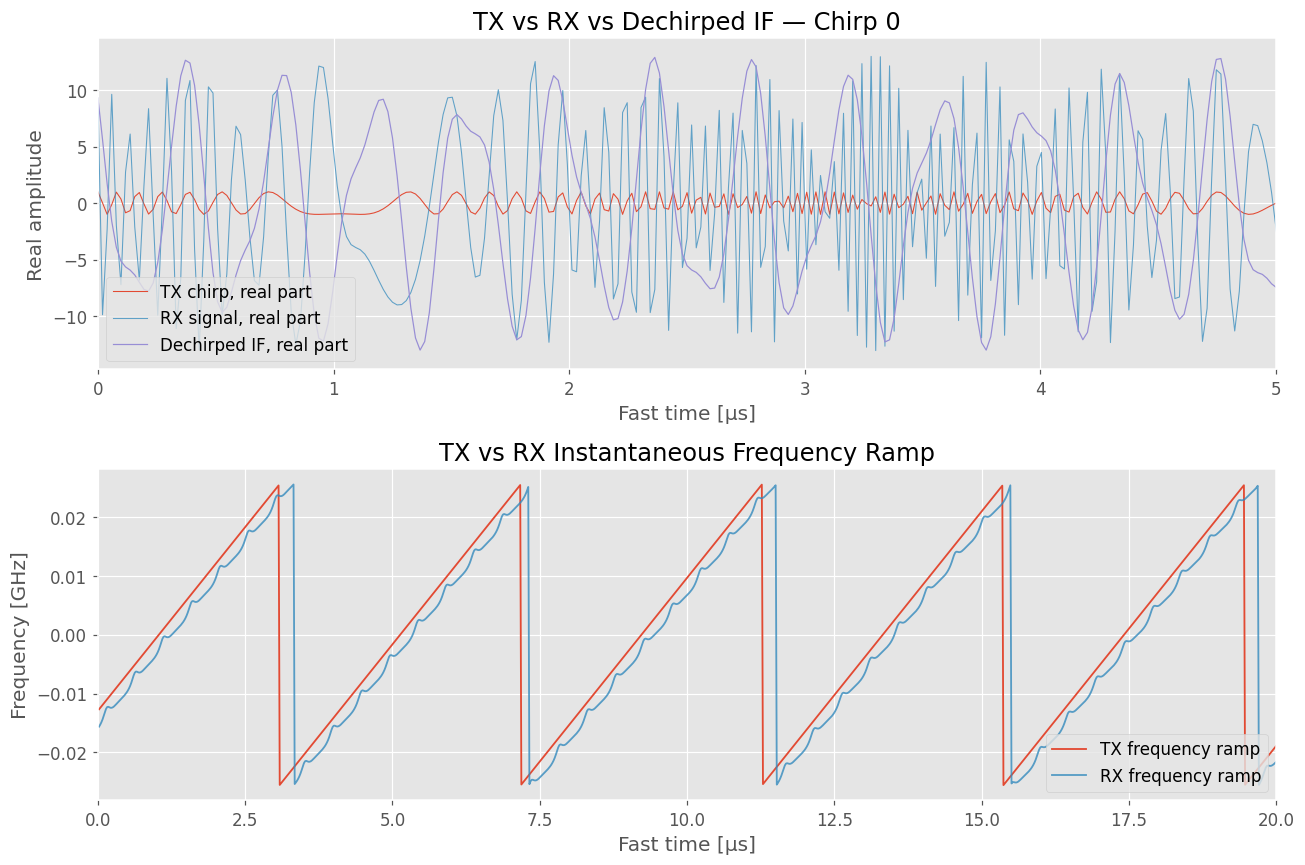

In [16]:
# ── Sampling axes ─────────────────────────────────────────────────────────────
t_fast = np.arange(N) / fs
t_abs = np.arange(M)[:, None] * Tc + t_fast[None, :]
t_chirp = t_fast[None, :]

# ── FFT axes ──────────────────────────────────────────────────────────────────
freq_axis = np.fft.fftfreq(N, d=1/fs)[:N//2]
range_axis = freq_axis * c / (2 * slope)

doppler_axis = np.fft.fftshift(np.fft.fftfreq(M, d=Tc))
velocity_axis = doppler_axis * wavelength / 2

# ── AWGN helper ────────────────────────────────────────────────────────────────
def add_awgn(x, snr_db, seed=None):
    rng = np.random.default_rng(seed)

    signal_power = np.mean(np.abs(x)**2)
    noise_power = signal_power / (10 ** (snr_db / 10))

    noise = np.sqrt(noise_power / 2) * (
        rng.standard_normal(x.shape) + 1j * rng.standard_normal(x.shape)
    )

    return x + noise

# ── TX chirp: complex analytic FMCW signal ────────────────────────────────────
tx = np.exp(
    1j * 2*pi * (
        f * t_abs
        + 0.5 * slope * t_chirp**2
    )
)

# ── RX signal: delayed versions of TX from each moving target ─────────────────
rx = np.zeros((M, N), dtype=np.complex128)

for R0, v, amp_db in targets:
    amp = 10 ** (amp_db / 20)

    # positive velocity = moving away from radar
    R_t = R0 + v * t_abs
    tau = 2 * R_t / c

    rx += amp * np.exp(
        1j * 2*pi * (
            f * (t_abs - tau)
            + 0.5 * slope * (t_chirp - tau)**2
        )
    )

# ── Dechirping / mixing ───────────────────────────────────────────────────────
# Convention chosen so positive range gives positive beat frequency.
cpi = tx * np.conj(rx)

# ── Default noisy CPI for later sections ──────────────────────────────────────
cpi_noisy = add_awgn(cpi, DEFAULT_SNR_DB, seed=42)

# ── Windowing before Range FFT ────────────────────────────────────────────────
window = signal.windows.blackman(N)

print(f"TX shape:  {tx.shape}")
print(f"RX shape:  {rx.shape}")
print(f"IF shape:  {cpi.shape}")
print(f"Range axis: 0 → {range_axis[-1]:.1f} m")
print(f"Velocity axis: {velocity_axis[0]:.2f} → {velocity_axis[-1]:.2f} m/s")
print(f"Default SNR for noisy RD map: {DEFAULT_SNR_DB} dB")

# ── TX / RX / IF visual check + chirp frequency ramp ──────────────────────────
tx_phase = np.unwrap(np.angle(tx[0]))
rx_phase = np.unwrap(np.angle(rx[0]))

tx_inst_freq = np.diff(tx_phase) / (2 * np.pi) * fs
rx_inst_freq = np.diff(rx_phase) / (2 * np.pi) * fs

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# Plot 1: waveform comparison
ax[0].plot(t_fast * 1e6, np.real(tx[0]), lw=0.7, label="TX chirp, real part")
ax[0].plot(t_fast * 1e6, np.real(rx[0]), lw=0.7, label="RX signal, real part", alpha=0.75)
ax[0].plot(t_fast * 1e6, np.real(cpi[0]), lw=0.8, label="Dechirped IF, real part")

ax[0].set_xlim(0, 5)
ax[0].set_title("TX vs RX vs Dechirped IF — Chirp 0")
ax[0].set_xlabel("Fast time [µs]")
ax[0].set_ylabel("Real amplitude")
ax[0].legend()
ax[0].grid(True)

# Plot 2: TX and RX instantaneous frequency ramps
ax[1].plot(
    t_fast[1:] * 1e6,
    tx_inst_freq / 1e9,
    lw=1.2,
    label="TX frequency ramp"
)

ax[1].plot(
    t_fast[1:] * 1e6,
    rx_inst_freq / 1e9,
    lw=1.2,
    label="RX frequency ramp",
    alpha=0.8
)

ax[1].set_title("TX vs RX Instantaneous Frequency Ramp")
ax[1].set_xlabel("Fast time [µs]")
ax[1].set_ylabel("Frequency [GHz]")
ax[1].legend()
ax[1].set_xlim(0, 20)
ax[1].grid(True)

plt.tight_layout()
plt.show()


## Step 4 — Range FFT (single chirp preview)

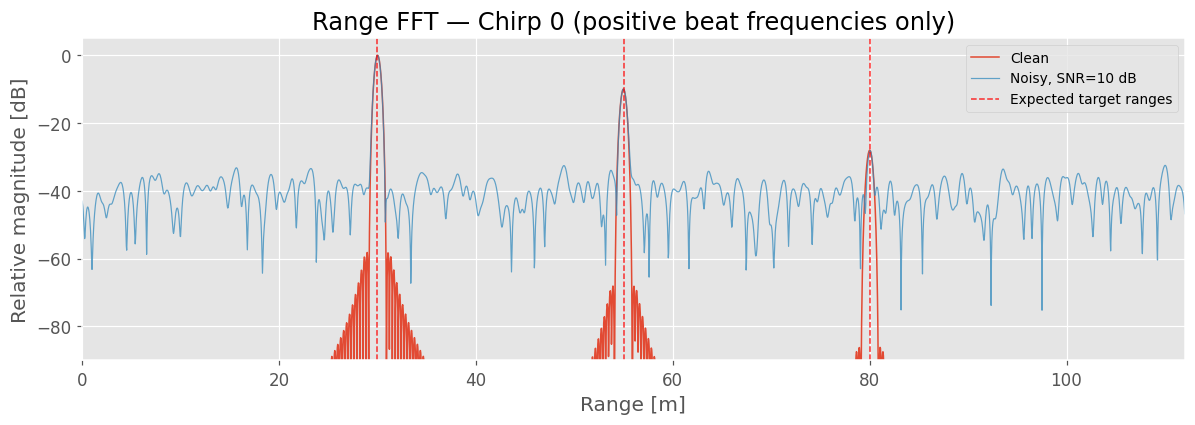

In [17]:
# Zero-pad for a finer visual grid on the 1D plot only.
# Zero-padding interpolates the FFT display; it does not improve physical range resolution.
fft_len = N * 8
freq_zp = np.fft.fftfreq(fft_len, d=1/fs)[:fft_len//2]
range_zp = freq_zp * c / (2 * slope)

# Use a real range window here. Do not rely on cpi_windowed from the RD helper;
# that variable is local inside compute_rd_map().
range_window = signal.windows.blackman(N)

X_clean = fft(cpi[0] * range_window, n=fft_len)[:fft_len//2]
X_noisy = fft(cpi_noisy[0] * range_window, n=fft_len)[:fft_len//2]

X_clean_db = 20 * np.log10(np.abs(X_clean) / np.max(np.abs(X_clean)) + 1e-12)
X_noisy_db = 20 * np.log10(np.abs(X_noisy) / np.max(np.abs(X_noisy)) + 1e-12)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(range_zp, X_clean_db, lw=1.0, label="Clean")
ax.plot(range_zp, X_noisy_db, lw=0.8, alpha=0.75, label=f"Noisy, SNR={DEFAULT_SNR_DB} dB")

for i, (r, v, p) in enumerate(targets):
    ax.axvline(
        r,
        color="red",
        ls="--",
        lw=1.0,
        alpha=0.8,
        label="Expected target ranges" if i == 0 else None,
    )

ax.set_xlim([0, max(r for r, v, p in targets) * 1.4])
ax.set_ylim([-90, 5])
ax.set_title("Range FFT — Chirp 0 (positive beat frequencies only)")
ax.set_xlabel("Range [m]")
ax.set_ylabel("Relative magnitude [dB]")
ax.legend(fontsize=9)
ax.grid(True)
plt.tight_layout()
plt.show()


## Step 5 — 2D FFT → Range-Doppler Map

The processing is intentionally split into two explicit FFTs:

1. **Range FFT** across fast-time samples inside each chirp.
2. **Doppler FFT** across chirps for each range bin.

Only the Doppler axis is `fftshift`ed, because velocity can be positive or negative. Range remains positive.

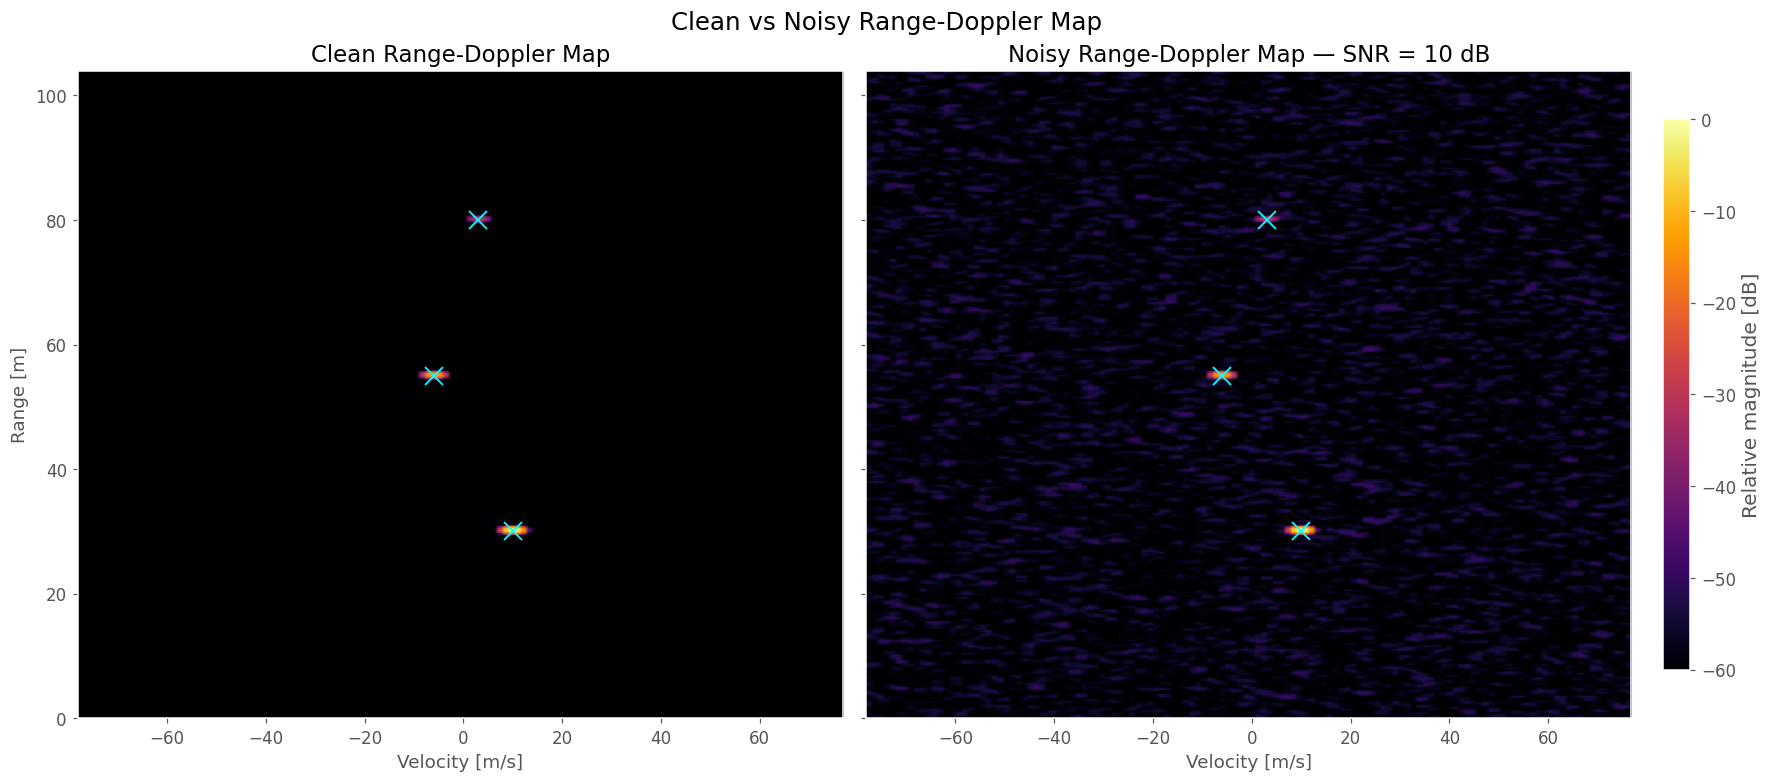

Clean RD median floor: -198.25 dB
Noisy RD median floor at 10 dB SNR: -60.03 dB
Clean peak-to-floor contrast: 198.25 dB
Noisy peak-to-floor contrast: 60.03 dB


In [18]:
# ── RD Map helper with 2D windowing ───────────────────────────────────────────
def compute_rd_map(cpi_input):
    # Range window: across fast-time samples
    range_window = signal.windows.blackman(N)

    # Doppler window: across chirps / slow time
    doppler_window = signal.windows.blackman(M)

    # 2D window: shape = (M, N)
    window_2d = doppler_window[:, None] * range_window[None, :]

    cpi_windowed = cpi_input * window_2d

    # Range FFT: across fast-time samples, axis=1
    range_fft = np.fft.fft(cpi_windowed, axis=1)
    range_fft = range_fft[:, :N//2]

    # Doppler FFT: across chirps, axis=0
    rd_complex = np.fft.fftshift(
        np.fft.fft(range_fft, axis=0),
        axes=0
    )

    # rows = range bins, columns = velocity bins
    rd_mag = np.abs(rd_complex).T
    rd_db = 20 * np.log10(rd_mag / np.max(rd_mag) + 1e-12)

    return rd_db, rd_complex


# ── Compute clean and noisy RD maps ───────────────────────────────────────────
rd_clean_db, rd_clean_complex = compute_rd_map(cpi)
rd_noisy_db, rd_noisy_complex = compute_rd_map(add_awgn(cpi, DEFAULT_SNR_DB, seed=42))

# Keep noisy RD as default for later sections
rd_db = rd_noisy_db
rd_complex = rd_noisy_complex
rd_mag = np.abs(rd_complex).T  # rows = range bins, columns = velocity bins

extent = [
    velocity_axis[0],
    velocity_axis[-1],
    range_axis[0],
    range_axis[-1]
]

r_plot_max = max(r for r, v, p in targets) * 1.3


# ── Plot clean vs noisy RD map ────────────────────────────────────────────────
fig, ax = plt.subplots(
    1,
    2,
    figsize=(16, 7),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

common_plot_kwargs = dict(
    aspect="auto",
    extent=extent,
    origin="lower",
    cmap="inferno",
    vmax=0,
    vmin=-60,
)

im0 = ax[0].imshow(rd_clean_db, **common_plot_kwargs)
ax[0].set_title("Clean Range-Doppler Map", fontsize=15)
ax[0].set_xlabel("Velocity [m/s]", fontsize=12)
ax[0].set_ylabel("Range [m]", fontsize=12)
ax[0].set_ylim([0, r_plot_max])

im1 = ax[1].imshow(rd_noisy_db, **common_plot_kwargs)
ax[1].set_title(f"Noisy Range-Doppler Map — SNR = {DEFAULT_SNR_DB} dB", fontsize=15)
ax[1].set_xlabel("Velocity [m/s]", fontsize=12)
ax[1].set_ylim([0, r_plot_max])

for axis in ax:
    for r, v, p in targets:
        axis.plot(
            v,
            r,
            marker="x",
            color="cyan",
            linestyle="None",
            ms=12,
            mew=1.2,
        )

    axis.grid(False)

# One clean colorbar on the far right
cbar = fig.colorbar(
    im1,
    ax=ax,
    location="right",
    shrink=0.85,
    pad=0.02
)
cbar.set_label("Relative magnitude [dB]")

fig.suptitle("Clean vs Noisy Range-Doppler Map", fontsize=16)
plt.show()


# ── Simple numeric noise-floor check ──────────────────────────────────────────
clean_floor = np.median(rd_clean_db)
noisy_floor = np.median(rd_noisy_db)

print(f"Clean RD median floor: {clean_floor:.2f} dB")
print(f"Noisy RD median floor at {DEFAULT_SNR_DB} dB SNR: {noisy_floor:.2f} dB")
print(f"Clean peak-to-floor contrast: {0 - clean_floor:.2f} dB")
print(f"Noisy peak-to-floor contrast: {0 - noisy_floor:.2f} dB")


## Step 6 — 3D Range-Doppler Surface Plot


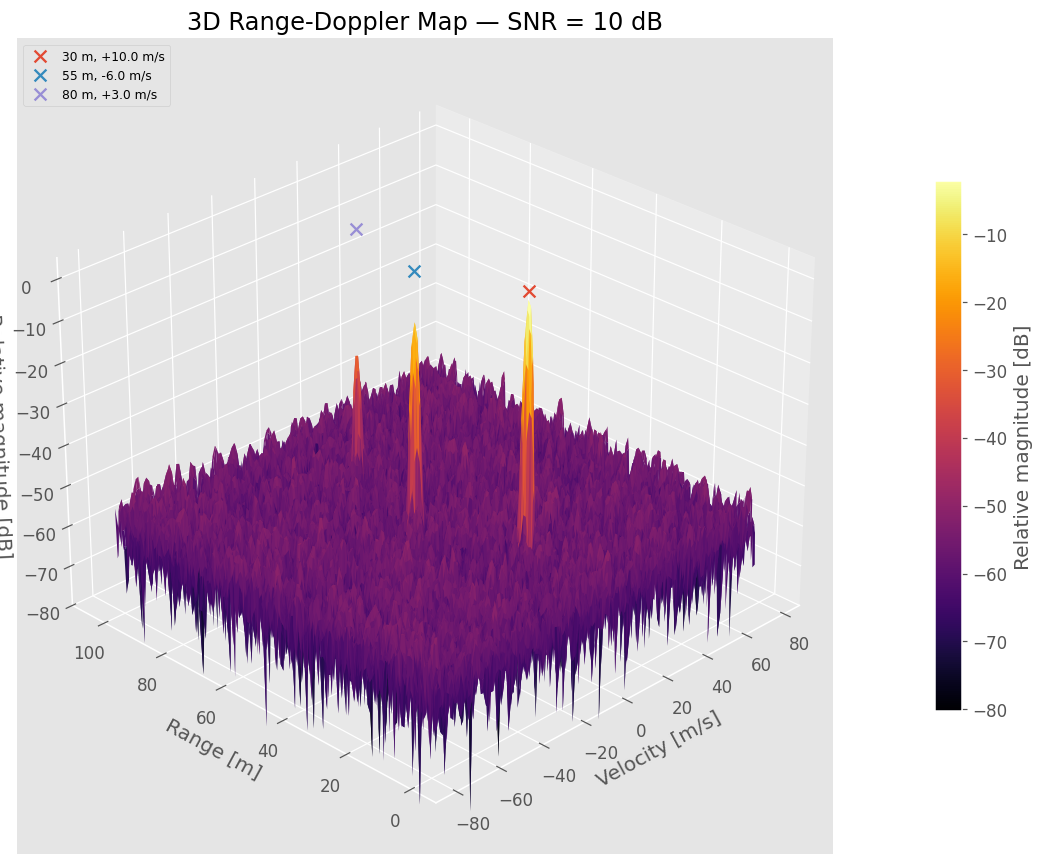

In [19]:
# ── 3D RD surface plot ───────────────────────────────────────────────────────
# Keep this decimated. Plotting every bin in 3D is slow and visually messy.
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

r_mask = range_axis <= r_plot_max
range_3d = range_axis[r_mask]
velocity_3d = velocity_axis
rd_3d = rd_db[r_mask, :]

# Decimation factors for readable plotting
r_step = max(1, len(range_3d) // 220)
v_step = max(1, len(velocity_3d) // 160)

R_mesh, V_mesh = np.meshgrid(
    range_3d[::r_step],
    velocity_3d[::v_step],
    indexing="ij"
)
Z = rd_3d[::r_step, ::v_step]

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    V_mesh,
    R_mesh,
    Z,
    cmap="inferno",
    linewidth=0,
    antialiased=True,
    rstride=1,
    cstride=1,
)

for r, v, p in targets:
    ax.scatter(v, r, 2, marker="x", s=60, label=f"{r:.0f} m, {v:+.1f} m/s")

ax.set_title(f"3D Range-Doppler Map — SNR = {DEFAULT_SNR_DB} dB")
ax.set_xlabel("Velocity [m/s]")
ax.set_ylabel("Range [m]")
ax.set_zlabel("Relative magnitude [dB]")
ax.set_zlim(-80, 5)
ax.view_init(elev=28, azim=-135)
fig.colorbar(surf, ax=ax, shrink=0.65, pad=0.08, label="Relative magnitude [dB]")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()


## Step 7 — Interactive Range-Doppler Map

In [20]:
if not HAS_WIDGETS:
    print(
        "ipywidgets is not installed, so the interactive RD map is skipped. "
        "The static RD maps above are still valid."
    )

else:
    r_plot_max = max(r for r, v, p in targets) * 1.3

    # ── New SNR slider ────────────────────────────────────────────────────────
    w_snr = widgets.FloatSlider(
        value=10,
        min=-20,
        max=30,
        step=1,
        description="SNR [dB]",
        continuous_update=False,
        style={"description_width": "110px"}
    )

    w_vmin = widgets.FloatSlider(
        value=-60,
        min=-100,
        max=0,
        step=1,
        description="Floor [dB]",
        continuous_update=False,
        style={"description_width": "110px"}
    )

    w_vmax = widgets.FloatSlider(
        value=0,
        min=-20,
        max=10,
        step=0.5,
        description="Ceiling [dB]",
        continuous_update=False,
        style={"description_width": "110px"}
    )

    w_rmax = widgets.FloatSlider(
        value=r_plot_max,
        min=10,
        max=range_axis[-1],
        step=1,
        description="Max range [m]",
        continuous_update=False,
        style={"description_width": "110px"}
    )

    w_vmax2 = widgets.FloatSlider(
        value=max_vel,
        min=1,
        max=max_vel,
        step=0.5,
        description="Max vel [m/s]",
        continuous_update=False,
        style={"description_width": "110px"}
    )

    w_cmap = widgets.Dropdown(
        options=["viridis", "plasma", "inferno", "hot", "coolwarm", "jet"],
        value="inferno",
        description="Colormap",
        style={"description_width": "80px"}
    )

    w_marks = widgets.Checkbox(
        value=True,
        description="Show target markers"
    )

    w_marker_color = widgets.Dropdown(
        options=[
            ("Red", "r"),
            ("Blue", "b"),
            ("Green", "g"),
            ("Black", "k"),
            ("White", "w"),
            ("Yellow", "y"),
            ("Cyan", "c"),
            ("Magenta", "m"),
        ],
        value="c",
        description="Marker color",
        style={"description_width": "100px"}
    )

    w_marker_size = widgets.FloatSlider(
        value=12,
        min=4,
        max=30,
        step=1,
        description="Marker size",
        continuous_update=False,
        style={"description_width": "100px"}
    )

    w_marker_width = widgets.FloatSlider(
        value=1.2,
        min=0.5,
        max=6,
        step=0.5,
        description="Marker width",
        continuous_update=False,
        style={"description_width": "100px"}
    )

    out = widgets.Output()

    def draw_plot():
        with out:
            out.clear_output(wait=True)

            # Recompute noisy RD map using current SNR
            current_snr = w_snr.value
            cpi_current = add_awgn(cpi, current_snr, seed=42)
            rd_current_db, _ = compute_rd_map(cpi_current)

            fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)

            im = ax.imshow(
                rd_current_db,
                aspect="auto",
                extent=extent,
                origin="lower",
                cmap=w_cmap.value,
                vmin=w_vmin.value,
                vmax=w_vmax.value,
            )

            ax.set_ylim([0, w_rmax.value])
            ax.set_xlim([-w_vmax2.value, w_vmax2.value])

            ax.set_title(
                f"Range-Doppler Map with AWGN — SNR = {current_snr:.1f} dB",
                fontsize=14
            )
            ax.set_xlabel("Velocity [m/s]", fontsize=12)
            ax.set_ylabel("Range [m]", fontsize=12)

            if w_marks.value:
                for r, v, p in targets:
                    ax.plot(
                        v,
                        r,
                        marker="x",
                        color=w_marker_color.value,
                        linestyle="None",
                        ms=w_marker_size.value,
                        mew=w_marker_width.value,
                        label=f"({r:.0f} m, {v:+.1f} m/s)"
                    )

                ax.legend(
                    loc="upper right",
                    fontsize=8,
                    framealpha=0.7
                )

            ax.grid(False)

            cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
            cbar.set_label("Relative magnitude [dB]")

            display(fig)
            plt.close(fig)

            noise_floor = np.median(rd_current_db)

            print(f"SNR setting: {current_snr:.1f} dB")
            print(f"Median RD floor: {noise_floor:.2f} dB")
            print(f"Peak-to-floor contrast: {0 - noise_floor:.2f} dB")

    def on_widget_change(change):
        draw_plot()

    controls = [
        w_snr,
        w_vmin,
        w_vmax,
        w_rmax,
        w_vmax2,
        w_cmap,
        w_marks,
        w_marker_color,
        w_marker_size,
        w_marker_width,
    ]

    for widget in controls:
        widget.observe(on_widget_change, names="value")

    ui = widgets.VBox([
        widgets.HBox([w_snr]),
        widgets.HBox([w_vmin, w_vmax]),
        widgets.HBox([w_rmax, w_vmax2]),
        widgets.HBox([w_cmap, w_marks]),
        widgets.HBox([w_marker_color, w_marker_size, w_marker_width]),
    ])

    display(ui, out)

    draw_plot()

Output()

## Step 8 — Peak Validation

In [21]:
def validate_peaks(rd_mag, target_list, r_ax, v_ax, search_r=8, search_v=4):
    """Validate local RD peaks near expected target coordinates.

    rd_mag shape must be: rows = range bins, columns = velocity bins.
    """
    hdr = (f"{'#':>3} | {'R_exp':>7} | {'R_est':>7} | {'ΔR':>6} |"
           f" {'V_exp':>7} | {'V_est':>7} | {'ΔV':>6} | {'Rel dB':>7}")
    print(hdr)
    print('─' * len(hdr))
    for i, (r, v, p) in enumerate(target_list, 1):
        ri = np.argmin(np.abs(r_ax - r))
        vi = np.argmin(np.abs(v_ax - v))
        r0, r1 = max(0, ri-search_r), min(rd_mag.shape[0]-1, ri+search_r)
        v0, v1 = max(0, vi-search_v), min(rd_mag.shape[1]-1, vi+search_v)
        patch  = rd_mag[r0:r1+1, v0:v1+1]
        pr, pv = np.unravel_index(patch.argmax(), patch.shape)
        r_est  = r_ax[r0 + pr]
        v_est  = v_ax[v0 + pv]
        db_val = 20 * np.log10(patch.max() / rd_mag.max() + 1e-12)
        print(f"  {i:>1}  | {r:>7.2f} | {r_est:>7.2f} | {r_est-r:>+6.2f} |"
              f" {v:>7.2f} | {v_est:>7.2f} | {v_est-v:>+6.2f} | {db_val:>7.1f}")

print(f'Range res = {range_res:.3f} m   |   Vel res = {vel_res:.4f} m/s')
print()
validate_peaks(rd_mag, targets, range_axis, velocity_axis)


Range res = 0.300 m   |   Vel res = 1.2199 m/s

  # |   R_exp |   R_est |     ΔR |   V_exp |   V_est |     ΔV |  Rel dB
───────────────────────────────────────────────────────────────────────
  1  |   30.00 |   29.98 |  -0.02 |   10.00 |    9.76 |  -0.24 |     0.0
  2  |   55.00 |   54.86 |  -0.14 |   -6.00 |   -6.10 |  -0.10 |   -10.0
  3  |   80.00 |   80.04 |  +0.04 |    3.00 |    2.44 |  -0.56 |   -28.7


## Step 9 — Controlled RD Validation + Dataset Save Prototype

This section reuses the same radar parameters and RD processing chain, but changes the target scenarios deliberately. The goal is not detection yet. The goal is to prove that the Range-Doppler peak appears near the expected range and velocity coordinates.

It also saves one example frame as:

```text
outputs/example_frame/rd_map.npy
outputs/example_frame/labels.json
```

The `.npy` file is the RD map input. The `.json` file is the ground-truth label/answer key for that RD map.


Range res = 0.300 m   |   Vel res = 1.2199 m/s
Validation SNR = 10 dB

══════════════════════════════════════════════════════════════════════════════════════════
A — one stationary target
══════════════════════════════════════════════════════════════════════════════════════════
  # |   R_exp |   R_est |     ΔR |   V_exp |   V_est |     ΔV |  Rel dB
───────────────────────────────────────────────────────────────────────
  1  |   50.00 |   50.07 |  +0.07 |    0.00 |    0.00 |  +0.00 |     0.0


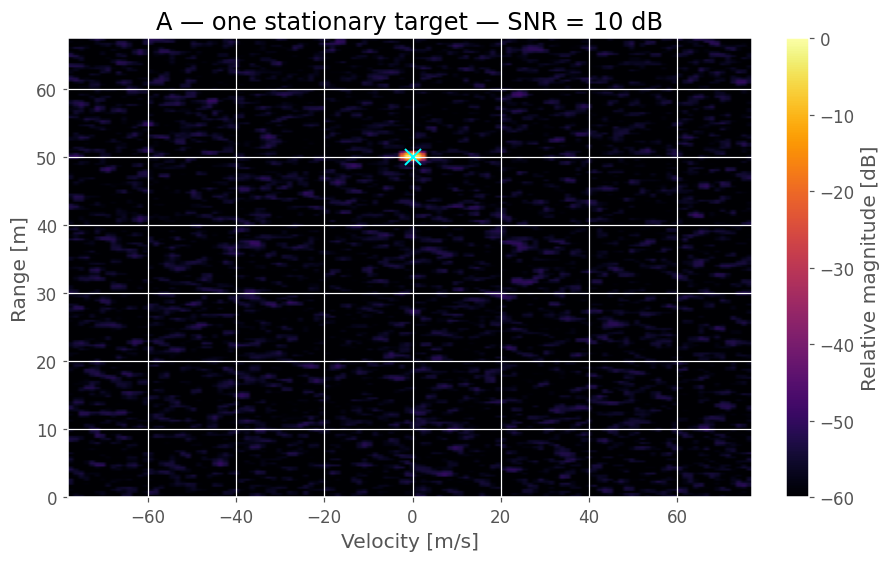


══════════════════════════════════════════════════════════════════════════════════════════
B — one target moving away
══════════════════════════════════════════════════════════════════════════════════════════
  # |   R_exp |   R_est |     ΔR |   V_exp |   V_est |     ΔV |  Rel dB
───────────────────────────────────────────────────────────────────────
  1  |   50.00 |   50.07 |  +0.07 |   10.00 |    9.76 |  -0.24 |     0.0


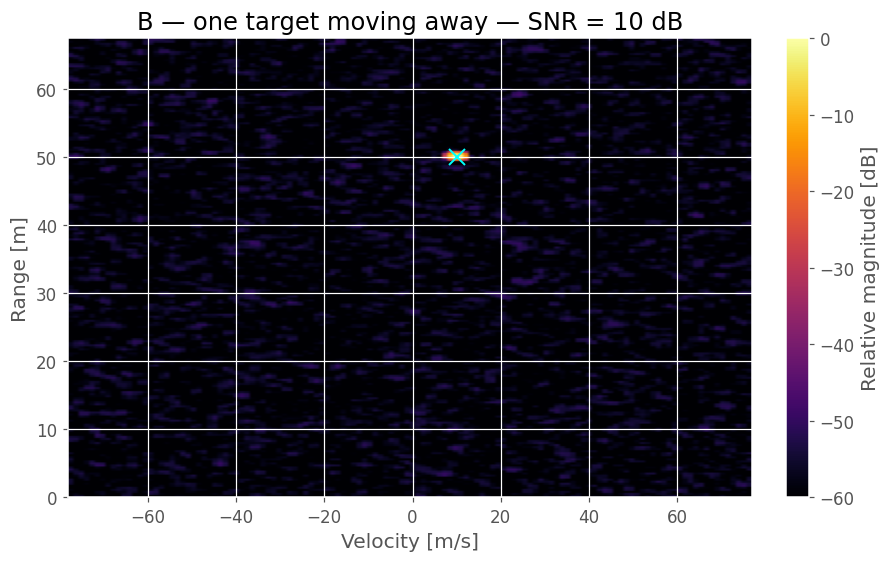


══════════════════════════════════════════════════════════════════════════════════════════
C — one target moving toward radar
══════════════════════════════════════════════════════════════════════════════════════════
  # |   R_exp |   R_est |     ΔR |   V_exp |   V_est |     ΔV |  Rel dB
───────────────────────────────────────────────────────────────────────
  1  |   50.00 |   50.07 |  +0.07 |  -10.00 |   -9.76 |  +0.24 |     0.0


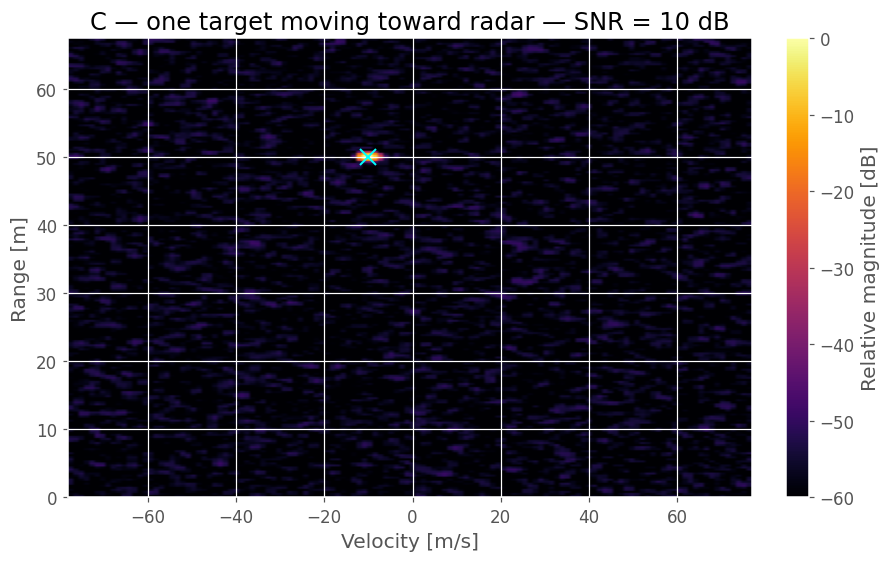


══════════════════════════════════════════════════════════════════════════════════════════
D — two targets, different ranges
══════════════════════════════════════════════════════════════════════════════════════════
  # |   R_exp |   R_est |     ΔR |   V_exp |   V_est |     ΔV |  Rel dB
───────────────────────────────────────────────────────────────────────
  1  |   30.00 |   29.98 |  -0.02 |    0.00 |    0.00 |  +0.00 |     0.0
  2  |   80.00 |   80.04 |  +0.04 |    0.00 |    0.00 |  +0.00 |    -0.1


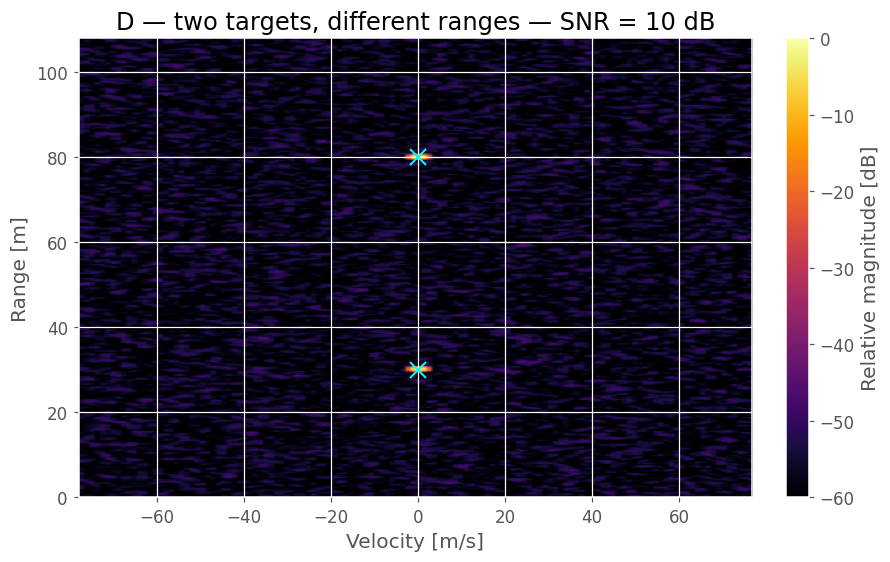


══════════════════════════════════════════════════════════════════════════════════════════
E — same range, different velocities
══════════════════════════════════════════════════════════════════════════════════════════
  # |   R_exp |   R_est |     ΔR |   V_exp |   V_est |     ΔV |  Rel dB
───────────────────────────────────────────────────────────────────────
  1  |   50.00 |   50.07 |  +0.07 |   -8.00 |   -8.54 |  -0.54 |    -0.5
  2  |   50.00 |   50.07 |  +0.07 |    8.00 |    8.54 |  +0.54 |     0.0


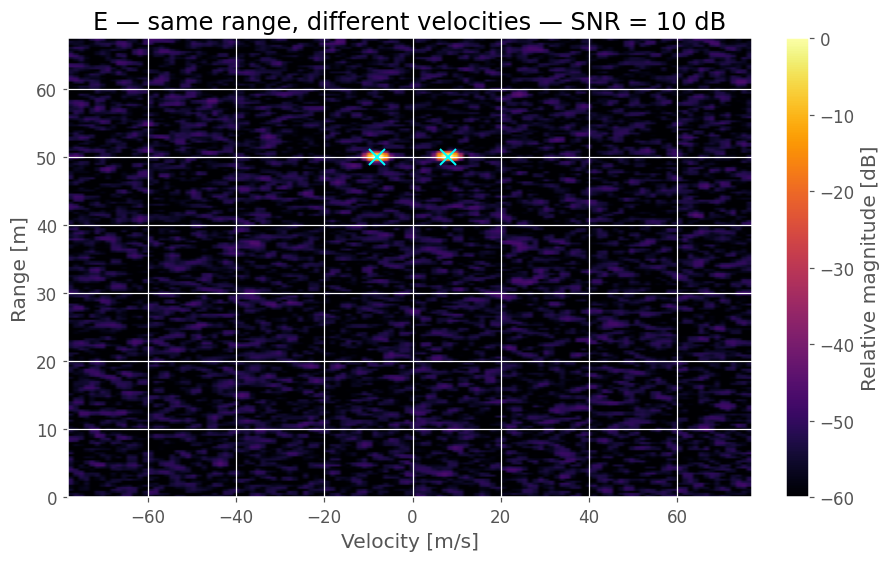

In [22]:
from pathlib import Path
import json

# ── Validation helpers ───────────────────────────────────────────────────────
def simulate_cpi_for_targets(target_list):
    """Build a clean dechirped CPI for an arbitrary target list.

    target_list format: [(range_m, velocity_mps, amplitude_db), ...]
    Uses the same FMCW parameters and axes defined earlier in the notebook.
    """
    rx_case = np.zeros((M, N), dtype=np.complex128)

    for R0, v, amp_db in target_list:
        amp = db_to_amp(amp_db)

        # positive velocity = moving away from radar
        R_t = R0 + v * t_abs
        tau = 2 * R_t / c

        rx_case += amp * np.exp(
            1j * 2*pi * (
                f * (t_abs - tau)
                + 0.5 * slope * (t_chirp - tau)**2
            )
        )

    # Same dechirping convention used earlier.
    return tx * np.conj(rx_case)


def rd_mag_from_db_complex(rd_complex_case):
    """Return RD magnitude in the same orientation expected by validate_peaks()."""
    return np.abs(rd_complex_case).T


def expected_label_for_targets(target_list):
    """Create the ground-truth label dictionary for a target list."""
    label_targets = []

    for r, v, amp_db in target_list:
        r_bin = int(np.argmin(np.abs(range_axis - r)))
        v_bin = int(np.argmin(np.abs(velocity_axis - v)))

        label_targets.append({
            "range_m": float(r),
            "velocity_mps": float(v),
            "amplitude_db": float(amp_db),
            "range_bin": r_bin,
            "velocity_bin": v_bin,
            "nearest_range_axis_m": float(range_axis[r_bin]),
            "nearest_velocity_axis_mps": float(velocity_axis[v_bin]),
        })

    return label_targets


def plot_rd_validation_case(rd_db_case, target_list, title, vmin=-60, vmax=0):
    """Compact RD plot with expected target markers."""
    local_r_plot_max = max(r for r, _, _ in target_list) * 1.35 if target_list else 100

    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    im = ax.imshow(
        rd_db_case,
        aspect="auto",
        extent=extent,
        origin="lower",
        cmap="inferno",
        vmin=vmin,
        vmax=vmax,
    )

    for r, v, _ in target_list:
        ax.plot(v, r, marker="x", color="cyan", linestyle="None", ms=10, mew=1.3)

    ax.set_ylim(0, local_r_plot_max)
    ax.set_title(title)
    ax.set_xlabel("Velocity [m/s]")
    ax.set_ylabel("Range [m]")
    fig.colorbar(im, ax=ax, label="Relative magnitude [dB]")
    plt.show()


# ── Controlled validation cases ──────────────────────────────────────────────
validation_cases = {
    "A — one stationary target": [(50, 0, 0)],
    "B — one target moving away": [(50, 10, 0)],
    "C — one target moving toward radar": [(50, -10, 0)],
    "D — two targets, different ranges": [(30, 0, 0), (80, 0, 0)],
    "E — same range, different velocities": [(50, -8, 0), (50, 8, 0)],
}

print(f"Range res = {range_res:.3f} m   |   Vel res = {vel_res:.4f} m/s")
print(f"Validation SNR = {DEFAULT_SNR_DB} dB")

for case_name, case_targets in validation_cases.items():
    print("\n" + "═" * 90)
    print(case_name)
    print("═" * 90)

    cpi_case = simulate_cpi_for_targets(case_targets)
    cpi_case_noisy = add_awgn(cpi_case, DEFAULT_SNR_DB, seed=42)
    rd_case_db, rd_case_complex = compute_rd_map(cpi_case_noisy)
    rd_case_mag = rd_mag_from_db_complex(rd_case_complex)

    validate_peaks(rd_case_mag, case_targets, range_axis, velocity_axis)
    plot_rd_validation_case(rd_case_db, case_targets, f"{case_name} — SNR = {DEFAULT_SNR_DB} dB")


### SNR sweep validation

This sweep checks when the RD peak becomes unstable as noise increases. It uses one moving target only, because debugging five targets at low SNR is how people invent fake conclusions.


In [23]:
# ── SNR sweep on one controlled target ────────────────────────────────────────
snr_test_target = [(50, 10, 0)]
snr_values = [20, 10, 5, 0, -5, -10]

print(f"Range res = {range_res:.3f} m   |   Vel res = {vel_res:.4f} m/s")

for snr_db in snr_values:
    print("\n" + "─" * 90)
    print(f"SNR = {snr_db:+.0f} dB")
    print("─" * 90)

    cpi_snr = simulate_cpi_for_targets(snr_test_target)
    cpi_snr_noisy = add_awgn(cpi_snr, snr_db, seed=42)
    rd_snr_db, rd_snr_complex = compute_rd_map(cpi_snr_noisy)
    rd_snr_mag = rd_mag_from_db_complex(rd_snr_complex)

    validate_peaks(rd_snr_mag, snr_test_target, range_axis, velocity_axis)


Range res = 0.300 m   |   Vel res = 1.2199 m/s

──────────────────────────────────────────────────────────────────────────────────────────
SNR = +20 dB
──────────────────────────────────────────────────────────────────────────────────────────
  # |   R_exp |   R_est |     ΔR |   V_exp |   V_est |     ΔV |  Rel dB
───────────────────────────────────────────────────────────────────────
  1  |   50.00 |   50.07 |  +0.07 |   10.00 |    9.76 |  -0.24 |     0.0

──────────────────────────────────────────────────────────────────────────────────────────
SNR = +10 dB
──────────────────────────────────────────────────────────────────────────────────────────
  # |   R_exp |   R_est |     ΔR |   V_exp |   V_est |     ΔV |  Rel dB
───────────────────────────────────────────────────────────────────────
  1  |   50.00 |   50.07 |  +0.07 |   10.00 |    9.76 |  -0.24 |     0.0

──────────────────────────────────────────────────────────────────────────────────────────
SNR = +5 dB
───────────────────────

### Save one RD frame and its labels

This is a prototype for the dataset generator. For now it saves only one frame. Later, the dataset generator will repeat this thousands of times with randomized targets, SNR, clutter, and train/validation/test splits.


In [24]:
# ── Save one example frame + label file ───────────────────────────────────────
# This uses the current global `targets` scenario from the notebook.
example_snr_db = DEFAULT_SNR_DB
example_targets = targets

cpi_example = simulate_cpi_for_targets(example_targets)
cpi_example_noisy = add_awgn(cpi_example, example_snr_db, seed=42)
rd_example_db, rd_example_complex = compute_rd_map(cpi_example_noisy)

out_dir = Path("outputs/example_frame")
out_dir.mkdir(parents=True, exist_ok=True)

# RD map input for later detectors. Shape = [range_bins, velocity_bins].
np.save(out_dir / "rd_map.npy", rd_example_db.astype(np.float32))

labels = {
    "snr_db": float(example_snr_db),
    "rd_map_file": "rd_map.npy",
    "rd_map_shape": list(rd_example_db.shape),
    "range_resolution_m": float(range_res),
    "velocity_resolution_mps": float(vel_res),
    "range_axis_min_m": float(range_axis[0]),
    "range_axis_max_m": float(range_axis[-1]),
    "velocity_axis_min_mps": float(velocity_axis[0]),
    "velocity_axis_max_mps": float(velocity_axis[-1]),
    "targets": expected_label_for_targets(example_targets),
}

with open(out_dir / "labels.json", "w") as f_json:
    json.dump(labels, f_json, indent=2)

print("Saved example frame:")
print(f"  RD map : {out_dir / 'rd_map.npy'}")
print(f"  Labels : {out_dir / 'labels.json'}")
print()
print(json.dumps(labels, indent=2))


Saved example frame:
  RD map : outputs\example_frame\rd_map.npy
  Labels : outputs\example_frame\labels.json

{
  "snr_db": 10.0,
  "rd_map_file": "rd_map.npy",
  "rd_map_shape": [
    1024,
    128
  ],
  "range_resolution_m": 0.299792458,
  "velocity_resolution_mps": 1.2198586344401041,
  "range_axis_min_m": 0.0,
  "range_axis_max_m": 306.687684534,
  "velocity_axis_min_mps": -78.07095260416666,
  "velocity_axis_max_mps": 76.85109396972655,
  "targets": [
    {
      "range_m": 30.0,
      "velocity_mps": 10.0,
      "amplitude_db": 20.0,
      "range_bin": 100,
      "velocity_bin": 72,
      "nearest_range_axis_m": 29.9792458,
      "nearest_velocity_axis_mps": 9.758869075520833
    },
    {
      "range_m": 55.0,
      "velocity_mps": -6.0,
      "amplitude_db": 10.0,
      "range_bin": 183,
      "velocity_bin": 59,
      "nearest_range_axis_m": 54.862019814,
      "nearest_velocity_axis_mps": -6.09929317220052
    },
    {
      "range_m": 80.0,
      "velocity_mps": 3.0,
     

# Step 10 — CFAR Configuration


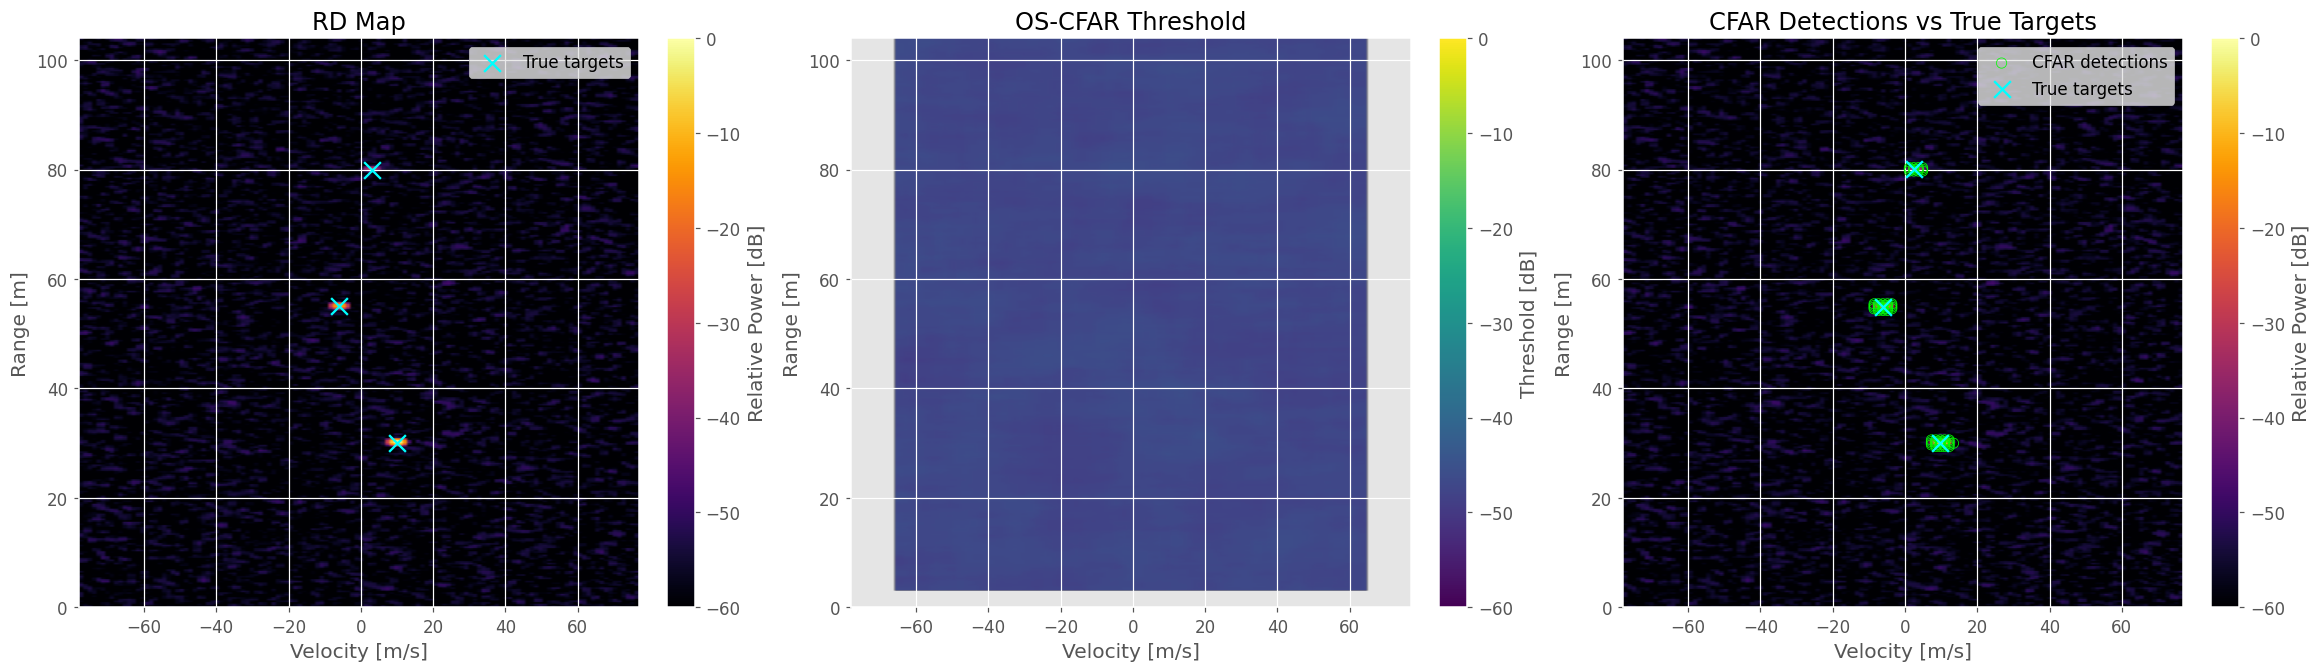

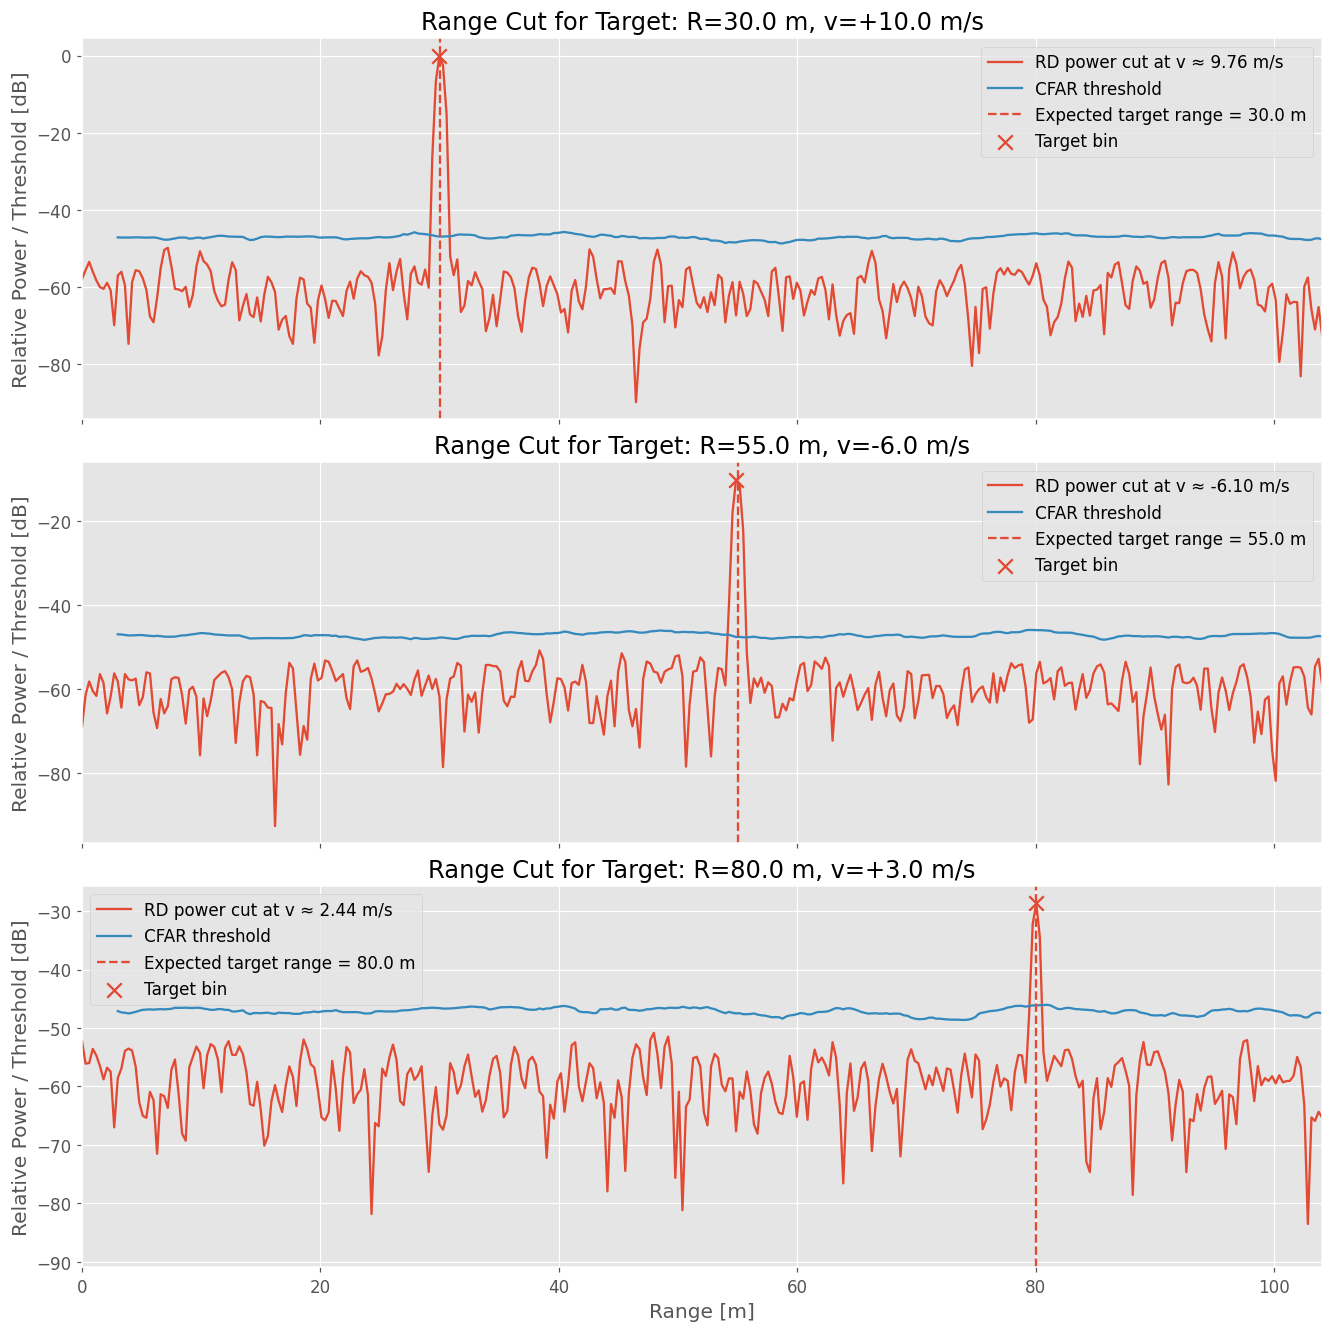

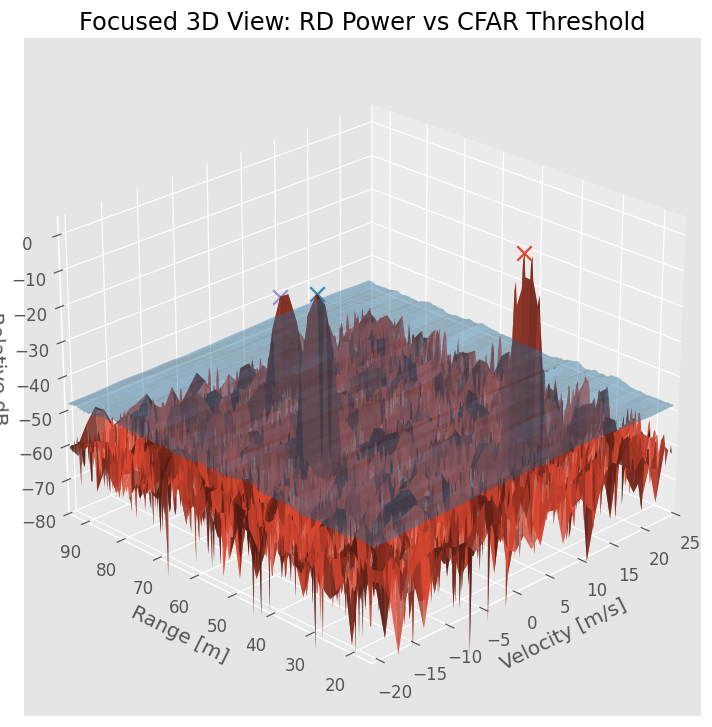

CFAR RESULTS
CFAR type: OS
Guard cells: range=2, doppler=2
Reference cells: range=8, doppler=8
Desired Pfa: 0.0001
Reference cells used: 416
OS rank: 312/416

True targets: 3
Total detections: 60
Correct detections: 3
Missed targets: 0
False alarms: 1
Measured Pfa approximation: 9.222370e-06


In [25]:
# ============================================================
# CFAR Detection on Range-Doppler Map
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

cfar_type = "OS"          # "CA", "GO", "OS"

guard_r = 2
guard_d = 2

ref_r = 8
ref_d = 8

desired_pfa = 1e-4
os_rank_fraction = 0.75

match_tol_r = 2
match_tol_d = 2

max_plot_range = r_plot_max
plot_3d = True

rd_power = rd_mag ** 2
num_r, num_d = rd_power.shape

threshold_map = np.full_like(rd_power, np.nan, dtype=float)
detection_mask = np.zeros_like(rd_power, dtype=bool)

window_r = 2 * (ref_r + guard_r) + 1
window_d = 2 * (ref_d + guard_d) + 1

guard_window_r = 2 * guard_r + 1
guard_window_d = 2 * guard_d + 1

num_ref_cells = window_r * window_d - guard_window_r * guard_window_d

alpha = num_ref_cells * (desired_pfa ** (-1 / num_ref_cells) - 1)

os_rank = int(np.ceil(os_rank_fraction * num_ref_cells))
os_rank = np.clip(os_rank, 1, num_ref_cells)

for r in range(ref_r + guard_r, num_r - ref_r - guard_r):
    for d in range(ref_d + guard_d, num_d - ref_d - guard_d):

        r0 = r - ref_r - guard_r
        r1 = r + ref_r + guard_r + 1

        d0 = d - ref_d - guard_d
        d1 = d + ref_d + guard_d + 1

        window = rd_power[r0:r1, d0:d1].copy()

        cut_r = ref_r + guard_r
        cut_d = ref_d + guard_d

        window[
            cut_r - guard_r : cut_r + guard_r + 1,
            cut_d - guard_d : cut_d + guard_d + 1
        ] = np.nan

        ref_cells = window[~np.isnan(window)]

        if cfar_type == "CA":
            noise_level = np.mean(ref_cells)

        elif cfar_type == "GO":
            left_cells = window[:, :cut_d - guard_d]
            right_cells = window[:, cut_d + guard_d + 1:]

            left_noise = np.nanmean(left_cells)
            right_noise = np.nanmean(right_cells)

            noise_level = max(left_noise, right_noise)

        elif cfar_type == "OS":
            sorted_cells = np.sort(ref_cells)
            noise_level = sorted_cells[os_rank - 1]

        else:
            raise ValueError("cfar_type must be 'CA', 'GO', or 'OS'")

        threshold = alpha * noise_level
        threshold_map[r, d] = threshold

        if rd_power[r, d] > threshold:
            detection_mask[r, d] = True

rd_power_db = 10 * np.log10(rd_power / np.nanmax(rd_power) + 1e-12)
threshold_db = 10 * np.log10(threshold_map / np.nanmax(rd_power) + 1e-12)

detected_bins = np.argwhere(detection_mask)

target_bins = []

for r_true, v_true, amp_db in targets:
    r_bin = int(np.argmin(np.abs(range_axis - r_true)))
    d_bin = int(np.argmin(np.abs(velocity_axis - v_true)))
    target_bins.append((r_bin, d_bin, r_true, v_true, amp_db))

matched_targets = set()
matched_detections = set()

for ti, (tr, td, _, _, _) in enumerate(target_bins):
    for di, (dr, dd) in enumerate(detected_bins):
        if abs(dr - tr) <= match_tol_r and abs(dd - td) <= match_tol_d:
            matched_targets.add(ti)
            matched_detections.add(di)

num_true_targets = len(target_bins)
num_detections = len(detected_bins)
num_correct = len(matched_targets)
num_missed = num_true_targets - num_correct
num_false_alarms = num_detections - len(matched_detections)

valid_cells = np.sum(~np.isnan(threshold_map))
measured_pfa = num_false_alarms / valid_cells if valid_cells > 0 else np.nan

det_r_bins = detected_bins[:, 0] if len(detected_bins) > 0 else []
det_d_bins = detected_bins[:, 1] if len(detected_bins) > 0 else []

target_r_bins = [x[0] for x in target_bins]
target_d_bins = [x[1] for x in target_bins]

fig, ax = plt.subplots(1, 3, figsize=(21, 6), constrained_layout=True)

im0 = ax[0].imshow(
    rd_power_db,
    aspect="auto",
    origin="lower",
    extent=extent,
    cmap="inferno",
    vmin=-60,
    vmax=0
)

ax[0].scatter(
    [v for _, _, _, v, _ in target_bins],
    [r for _, _, r, _, _ in target_bins],
    marker="x",
    s=120,
    color="cyan",
    label="True targets"
)

ax[0].set_title("RD Map")
ax[0].set_xlabel("Velocity [m/s]")
ax[0].set_ylabel("Range [m]")
ax[0].set_ylim(0, max_plot_range)
ax[0].legend()
fig.colorbar(im0, ax=ax[0], label="Relative Power [dB]")

im1 = ax[1].imshow(
    threshold_db,
    aspect="auto",
    origin="lower",
    extent=extent,
    cmap="viridis",
    vmin=-60,
    vmax=0
)

ax[1].set_title(f"{cfar_type}-CFAR Threshold")
ax[1].set_xlabel("Velocity [m/s]")
ax[1].set_ylabel("Range [m]")
ax[1].set_ylim(0, max_plot_range)
fig.colorbar(im1, ax=ax[1], label="Threshold [dB]")

im2 = ax[2].imshow(
    rd_power_db,
    aspect="auto",
    origin="lower",
    extent=extent,
    cmap="inferno",
    vmin=-60,
    vmax=0
)

if len(detected_bins) > 0:
    ax[2].scatter(
        velocity_axis[det_d_bins],
        range_axis[det_r_bins],
        marker="o",
        s=45,
        facecolors="none",
        edgecolors="lime",
        label="CFAR detections"
    )

ax[2].scatter(
    velocity_axis[target_d_bins],
    range_axis[target_r_bins],
    marker="x",
    s=120,
    color="cyan",
    label="True targets"
)

ax[2].set_title("CFAR Detections vs True Targets")
ax[2].set_xlabel("Velocity [m/s]")
ax[2].set_ylabel("Range [m]")
ax[2].set_ylim(0, max_plot_range)
ax[2].legend()
fig.colorbar(im2, ax=ax[2], label="Relative Power [dB]")

plt.show()

fig, axs = plt.subplots(
    len(target_bins),
    1,
    figsize=(12, 4 * len(target_bins)),
    sharex=True,
    constrained_layout=True
)

if len(target_bins) == 1:
    axs = [axs]

for ax_i, (r_bin, d_bin, r_true, v_true, amp_db) in zip(axs, target_bins):

    ax_i.plot(
        range_axis,
        rd_power_db[:, d_bin],
        label=f"RD power cut at v ≈ {velocity_axis[d_bin]:.2f} m/s"
    )

    ax_i.plot(
        range_axis,
        threshold_db[:, d_bin],
        label="CFAR threshold"
    )

    ax_i.axvline(
        r_true,
        linestyle="--",
        label=f"Expected target range = {r_true:.1f} m"
    )

    ax_i.scatter(
        range_axis[r_bin],
        rd_power_db[r_bin, d_bin],
        s=90,
        marker="x",
        label="Target bin"
    )

    ax_i.set_title(f"Range Cut for Target: R={r_true:.1f} m, v={v_true:+.1f} m/s")
    ax_i.set_ylabel("Relative Power / Threshold [dB]")
    ax_i.set_xlim(0, max_plot_range)
    ax_i.grid(True)
    ax_i.legend()

axs[-1].set_xlabel("Range [m]")
plt.show()

if plot_3d and len(target_bins) > 0:

    target_ranges = [r for _, _, r, _, _ in target_bins]
    target_vels = [v for _, _, _, v, _ in target_bins]

    r_min = max(0, min(target_ranges) - 15)
    r_max = min(range_axis[-1], max(target_ranges) + 15)

    v_min = max(velocity_axis[0], min(target_vels) - 15)
    v_max = min(velocity_axis[-1], max(target_vels) + 15)

    r_mask = (range_axis >= r_min) & (range_axis <= r_max)
    d_mask = (velocity_axis >= v_min) & (velocity_axis <= v_max)

    range_focus = range_axis[r_mask]
    velocity_focus = velocity_axis[d_mask]

    rd_focus = rd_power_db[np.ix_(r_mask, d_mask)]
    th_focus = threshold_db[np.ix_(r_mask, d_mask)]

    V_mesh, R_mesh = np.meshgrid(velocity_focus, range_focus)

    fig = plt.figure(figsize=(13, 8))
    ax3d = fig.add_subplot(111, projection="3d")

    ax3d.plot_surface(
        V_mesh,
        R_mesh,
        rd_focus,
        alpha=0.80,
        linewidth=0,
        antialiased=True
    )

    ax3d.plot_surface(
        V_mesh,
        R_mesh,
        th_focus,
        alpha=0.45,
        linewidth=0,
        antialiased=True
    )

    for r_bin, d_bin, r_true, v_true, amp_db in target_bins:
        if r_min <= r_true <= r_max and v_min <= v_true <= v_max:
            ax3d.scatter(
                velocity_axis[d_bin],
                range_axis[r_bin],
                rd_power_db[r_bin, d_bin],
                s=90,
                marker="x"
            )

    ax3d.set_title("Focused 3D View: RD Power vs CFAR Threshold")
    ax3d.set_xlabel("Velocity [m/s]")
    ax3d.set_ylabel("Range [m]")
    ax3d.set_zlabel("Relative dB")

    ax3d.set_xlim(v_min, v_max)
    ax3d.set_ylim(r_min, r_max)
    ax3d.set_zlim(-80, 5)

    ax3d.view_init(elev=25, azim=-135)

    plt.show()

print("CFAR RESULTS")
print("============")
print(f"CFAR type: {cfar_type}")
print(f"Guard cells: range={guard_r}, doppler={guard_d}")
print(f"Reference cells: range={ref_r}, doppler={ref_d}")
print(f"Desired Pfa: {desired_pfa}")
print(f"Reference cells used: {num_ref_cells}")

if cfar_type == "OS":
    print(f"OS rank: {os_rank}/{num_ref_cells}")

print()
print(f"True targets: {num_true_targets}")
print(f"Total detections: {num_detections}")
print(f"Correct detections: {num_correct}")
print(f"Missed targets: {num_missed}")
print(f"False alarms: {num_false_alarms}")
print(f"Measured Pfa approximation: {measured_pfa:.6e}")

GO : false alarms 7 : 6.4e-05
CA: false alarms 20 : 1.8e-4
OS: false alarms 1 : 9.2e-06